# Spotify Clustering 

In [4]:
import os
print(os.getcwd())

/Applications/Coding/3rd_Semester/Classroom/AI ML-1 Lab/PCA_2/Spotify-Music-Taste-Clustering/notebooks


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

## Load The Data Set

In [6]:
# Load dataset
df = pd.read_csv("/Applications/Coding/3rd_Semester/Classroom/AI ML-1 Lab/PCA_2/Spotify-Music-Taste-Clustering/dataset/spotify-tracks-dataset-detailed.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (114000, 20)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## Understand The Dataset

In [7]:
df.columns.tolist()

['track_id',
 'artists',
 'album_name',
 'track_name',
 'popularity',
 'duration_ms',
 'explicit',
 'danceability',
 'energy',
 'key',
 'loudness',
 'mode',
 'speechiness',
 'acousticness',
 'instrumentalness',
 'liveness',
 'valence',
 'tempo',
 'time_signature',
 'track_genre']

In [8]:
df.dtypes

track_id                str
artists                 str
album_name              str
track_name              str
popularity            int64
duration_ms           int64
explicit               bool
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_genre             str
dtype: object

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  str    
 1   artists           113999 non-null  str    
 2   album_name        113999 non-null  str    
 3   track_name        113999 non-null  str    
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           114000 non-nu

In [10]:
df.isnull().sum()

track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(450)

In [12]:
df.describe()

,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


## Data Quality Check

In [15]:
df.isnull().sum()[df.isnull().sum() > 0]

artists       1
album_name    1
track_name    1
dtype: int64

In [16]:
df.duplicated().sum()

np.int64(450)

In [17]:
df["track_id"].duplicated().sum()

np.int64(24259)

In [20]:
(df["duration_ms"] == 0).sum()

np.int64(1)

In [22]:
(df["tempo"] == 0).sum()

np.int64(157)

In [24]:
features = ["danceability", "energy", "acousticness", "tempo"]

df[features].describe().round(3)

,danceability,energy,acousticness,tempo
count,114000.000,114000.000,114000.000,114000.000
mean,0.567,0.641,0.315,122.148
std,0.174,0.252,0.333,29.978
min,0.000,0.000,0.000,0.000
25%,0.456,0.472,0.017,99.219
50%,0.580,0.685,0.169,122.017
75%,0.695,0.854,0.598,140.071
max,0.985,1.000,0.996,243.372


## Problematic Rows Investigate

In [26]:
# Inspect missing metadata rows
print("Rows with missing metadata:")
display(df[df[["artists", "album_name", "track_name"]].isnull().any(axis=1)])

Rows with missing metadata:


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


In [27]:
# Inspect zero tempo rows
print("\nRows with zero tempo:")
display(df[df["tempo"] == 0][
    ["track_id", "track_name", "artists", "tempo"]
].head(10))


Rows with zero tempo:


,track_id,track_name,artists,tempo
4131,59gg6zQhSKGVnkT3hWAY3l,The Departure,Max Richter;Lang Lang,0.0
4379,4acmzQsAeMJa5sGFSog7fu,The End of Childhood (feat. Jack Liebeck),Dario Marianelli;Jack Liebeck;Benjamin Wallfisch,0.0
4664,1Kb2DqjHRvOcT5xeWtz3t5,Ferme Les Yeux,Sylvain Chauveau,0.0
45670,6B9Mgf9smWqxDjA35VD6MK,Campomoro,Little Symphony,0.0
45720,7i5OoyPXtSrqz9jobJfG1F,Ritornello,Little Symphony,0.0
45729,0pTAEdockvKVSq1hhFqk7O,Amager,Little Symphony,0.0
45773,1keWmyG6qyBbMagPBdgUKr,Ionian,Little Symphony,0.0
59221,5BcyxCXrXuw4vsAqAiObWM,Yes! No! I Mean Yes! No I Don't!,Leila Bela,0.0
59310,6hsyfegVY5yklJneM40mWi,The Exorsism Begins...,Leila Bela,0.0
59473,48Nt8u7kYSTwE6axtE9hJO,Leaving Her Quantum Journey Behind...,Leila Bela,0.0


In [28]:
# Inspect duplicate track IDs
duplicate_ids = df[df["track_id"].duplicated(keep=False)]

print("\nDuplicate track ID examples:")
display(
    duplicate_ids.sort_values("track_id").head(10)[
        ["track_id", "track_name", "artists", "track_genre"]
    ]
)


Duplicate track ID examples:


,track_id,track_name,artists,track_genre
15028,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,chill
103211,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,soul
85578,001YQlnDSduXd5LgBd66gT,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,punk-rock
100420,001YQlnDSduXd5LgBd66gT,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,ska
2106,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,alt-rock
3257,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,alternative
91801,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,rock
33178,004h8smbIoAkUNDJvVKwkG,Lovemark,Ouse;Powfu,emo
94239,004h8smbIoAkUNDJvVKwkG,Lovemark,Ouse;Powfu,sad
35138,006rHBBNLJMpQs8fRC2GDe,Agora Estou Sofrendo - Ao Vivo,Calcinha Preta;Gusttavo Lima,forro


## Data Cleaning

In [30]:
# Create a clean copy
df_clean = df.copy()

In [31]:
# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

In [32]:
# Remove rows with missing track metadata
df_clean = df_clean.dropna(
    subset=["track_name", "artists"]
)

In [33]:
# Remove invalid tempo values
df_clean = df_clean[df_clean["tempo"] > 0].copy()

In [34]:
# Reset index
df_clean.reset_index(drop=True, inplace=True)

In [36]:
# Cleaning Report
print("Original Dataset:", df.shape)
print("Cleaned Dataset:", df_clean.shape)

print("\nRemaining Missing Values:")
print(df_clean.isnull().sum().sum())

print("Remaining Exact Duplicates:", df_clean.duplicated().sum())
print("Remaining Zero Tempo:", (df_clean["tempo"] <= 0).sum())

Original Dataset: (114000, 20)
Cleaned Dataset: (113392, 20)

Remaining Missing Values:
0
Remaining Exact Duplicates: 0
Remaining Zero Tempo: 0


## Feature Selection & Standardization

In [37]:
# Select numerical features
features = ["danceability", "energy", "acousticness", "tempo"]

X = df_clean[features]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert scaled data into DataFrame
X_scaled_df = pd.DataFrame(X_scaled, columns=features)

print("Original Feature Shape:", X.shape)
print("Scaled Feature Shape:", X_scaled_df.shape)

print("\nScaled Feature Statistics:")
print(X_scaled_df.describe().round(3))

Original Feature Shape: (113392, 4)
Scaled Feature Shape: (113392, 4)

Scaled Feature Statistics:
       danceability      energy  acousticness       tempo
count    113392.000  113392.000    113392.000  113392.000
mean         -0.000       0.000         0.000       0.000
std           1.000       1.000         1.000       1.000
min          -2.999      -2.568        -0.946      -3.108
25%          -0.643      -0.674        -0.895      -0.770
50%           0.077       0.173        -0.440      -0.011
75%           0.738       0.844         0.848       0.598
max           2.422       1.427         2.057       4.082


## Elbow Method (WCSS)

K = 1, WCSS = 80230.86
K = 2, WCSS = 51994.71
K = 3, WCSS = 40627.19
K = 4, WCSS = 35853.76
K = 5, WCSS = 31163.09
K = 6, WCSS = 27980.78
K = 7, WCSS = 25649.95
K = 8, WCSS = 23773.77
K = 9, WCSS = 22258.55
K = 10, WCSS = 21131.04


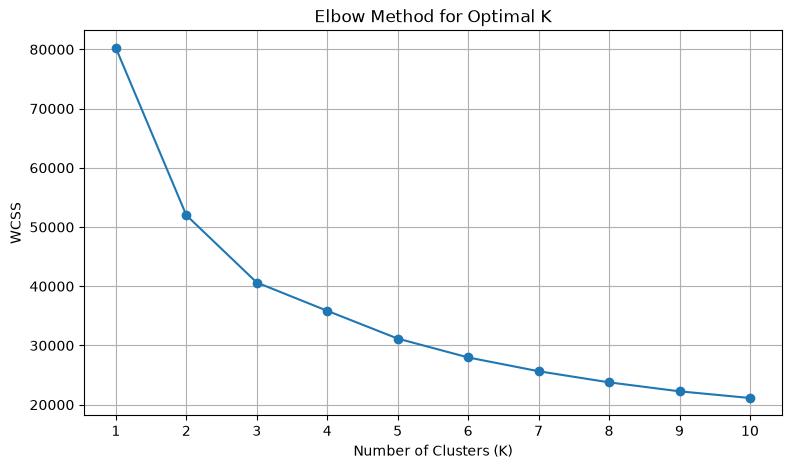

In [38]:
# Elbow Method

sample_data = X_scaled_df.sample(
    n=20000,
    random_state=42
)

wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=5,
        random_state=42
    )

    kmeans.fit(sample_data)
    wcss.append(kmeans.inertia_)

    print(f"K = {k}, WCSS = {kmeans.inertia_:.2f}")

# Plot Elbow Curve
plt.figure(figsize=(9, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method for Optimal K")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

## Silhouette Score

In [39]:
from sklearn.metrics import silhouette_score

silhouette_results = {}

silhouette_sample = sample_data.sample(
    n=5000,
    random_state=42
)

for k in [3, 4, 5, 6]:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=5
    )

    labels = kmeans.fit_predict(silhouette_sample)

    score = silhouette_score(
        silhouette_sample,
        labels
    )

    silhouette_results[k] = score

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 3, Silhouette Score = 0.2736
K = 4, Silhouette Score = 0.2536
K = 5, Silhouette Score = 0.2433
K = 6, Silhouette Score = 0.2504


## Train Final KMeans Model

In [40]:
# Train Final KMeans Model

final_kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=10,
    random_state=42
)

df_clean["Vibe_Cluster"] = final_kmeans.fit_predict(X_scaled)

print("Final Model Training Completed!")
print("\nCluster Distribution:")
print(df_clean["Vibe_Cluster"].value_counts().sort_index())

print("\nCluster Percentages:")
print(
    (df_clean["Vibe_Cluster"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

Final Model Training Completed!

Cluster Distribution:
Vibe_Cluster
0    29987
1    49904
2    33501
Name: count, dtype: int64

Cluster Percentages:
Vibe_Cluster
0    26.45
1    44.01
2    29.54
Name: proportion, dtype: float64


## Cluster Analysis

In [41]:
# Cluster-wise Feature Analysis

cluster_analysis = df_clean.groupby("Vibe_Cluster").agg(
    Track_Count=("track_name", "count"),
    Danceability=("danceability", "mean"),
    Energy=("energy", "mean"),
    Acousticness=("acousticness", "mean"),
    Tempo=("tempo", "mean")
).round(3)

print("Cluster Feature Analysis:")
display(cluster_analysis)

Cluster Feature Analysis:


,Track_Count,Danceability,Energy,Acousticness,Tempo
Vibe_Cluster,,,,,
0,29987,0.485,0.334,0.769,110.669
1,49904,0.683,0.715,0.174,110.963
2,33501,0.471,0.813,0.115,149.751


## Assign Human-Readable Vibe Names

In [42]:
# Map cluster IDs to human-readable vibe names

vibe_mapping = {
    0: "Acoustic & Mellow",
    1: "Danceable & Upbeat",
    2: "High-Energy & Fast-Paced"
}

df_clean["Vibe_Cluster_Label"] = (
    df_clean["Vibe_Cluster"].map(vibe_mapping)
)

# Verify labels
print("Vibe Labels Assigned Successfully!")

display(
    df_clean[
        ["track_name", "artists", "Vibe_Cluster", "Vibe_Cluster_Label"]
    ].head(10)
)

print("\nVibe Distribution:")
print(df_clean["Vibe_Cluster_Label"].value_counts())

Vibe Labels Assigned Successfully!


,track_name,artists,Vibe_Cluster,Vibe_Cluster_Label
0,Comedy,Gen Hoshino,1,Danceable & Upbeat
1,Ghost - Acoustic,Ben Woodward,0,Acoustic & Mellow
2,To Begin Again,Ingrid Michaelson;ZAYN,0,Acoustic & Mellow
3,Can't Help Falling In Love,Kina Grannis,0,Acoustic & Mellow
4,Hold On,Chord Overstreet,0,Acoustic & Mellow
5,Days I Will Remember,Tyrone Wells,1,Danceable & Upbeat
6,Say Something,A Great Big World;Christina Aguilera,0,Acoustic & Mellow
7,I'm Yours,Jason Mraz,0,Acoustic & Mellow
8,Lucky,Jason Mraz;Colbie Caillat,1,Danceable & Upbeat
9,Hunger,Ross Copperman,0,Acoustic & Mellow



Vibe Distribution:
Vibe_Cluster_Label
Danceable & Upbeat          49904
High-Energy & Fast-Paced    33501
Acoustic & Mellow           29987
Name: count, dtype: int64
